# Level 2 — Task 2: Time Series Analysis

**Assignment objectives:** plot time-series data and identify patterns; decompose into trend, seasonality, and residuals using `statsmodels`; perform moving-average smoothing and plot the result.

**Dataset:** the supplied stock-price file, filtered to AAPL (Apple) to keep one stock series. It contains 1,007 AAPL trading-day records from 2014-01-02 through 2017-12-29.

The source has trading-day observations, not observations on every calendar day. For seasonal decomposition, this notebook aggregates the last available close in each Friday-ending week to create a regular weekly series.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

## 1. Load and prepare the AAPL series

In [2]:
aapl = pd.read_csv("data/aapl_stock_prices.csv", parse_dates=["date"])
aapl = aapl.sort_values("date")

print("AAPL rows:", len(aapl))
print("Date range:", aapl["date"].min().date(), "to", aapl["date"].max().date())
aapl.head()

AAPL rows: 1007
Date range: 2014-01-02 to 2017-12-29


,symbol,date,open,high,low,close,volume
0,AAPL,2014-01-02,79.3828,79.5756,78.8601,79.0185,58791957
1,AAPL,2014-01-03,78.9799,79.0999,77.2042,77.2828,98303870
2,AAPL,2014-01-06,76.7785,78.1142,76.2285,77.7042,103359151
3,AAPL,2014-01-07,77.7599,77.9942,76.8464,77.1481,79432766
4,AAPL,2014-01-08,76.9728,77.9371,76.9556,77.6371,64686685


In [3]:
weekly_close = (
    aapl.set_index("date")["close"]
    .resample("W-FRI")
    .last()
    .dropna()
)

print("Weekly observations:", len(weekly_close))
print("Missing weekly values:", weekly_close.isna().sum())

Weekly observations: 209
Missing weekly values: 0


## 2. Plot the time series and inspect its pattern

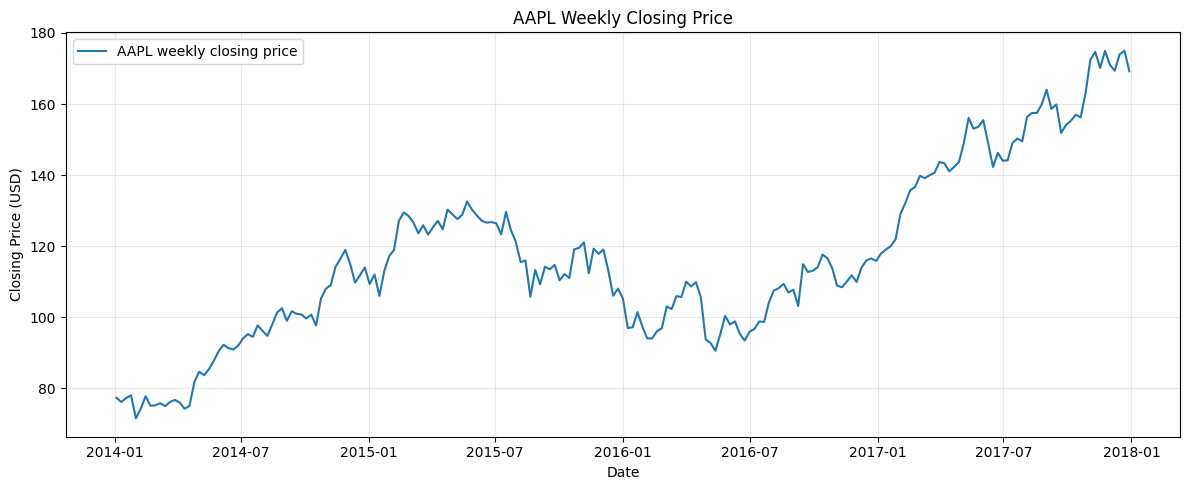

In [4]:
plt.figure(figsize=(12, 5))
plt.plot(weekly_close.index, weekly_close.values, label="AAPL weekly closing price")
plt.title("AAPL Weekly Closing Price")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Pattern to inspect:** look for the long-term direction of the closing price and any repeated movement across years. Avoid claiming a pattern that is not visible in the plot.

## 3. Decompose trend, seasonality, and residuals

The weekly series has enough observations for a 52-week seasonal period. The decomposition below separates the series into its trend, seasonal component, and residual component.

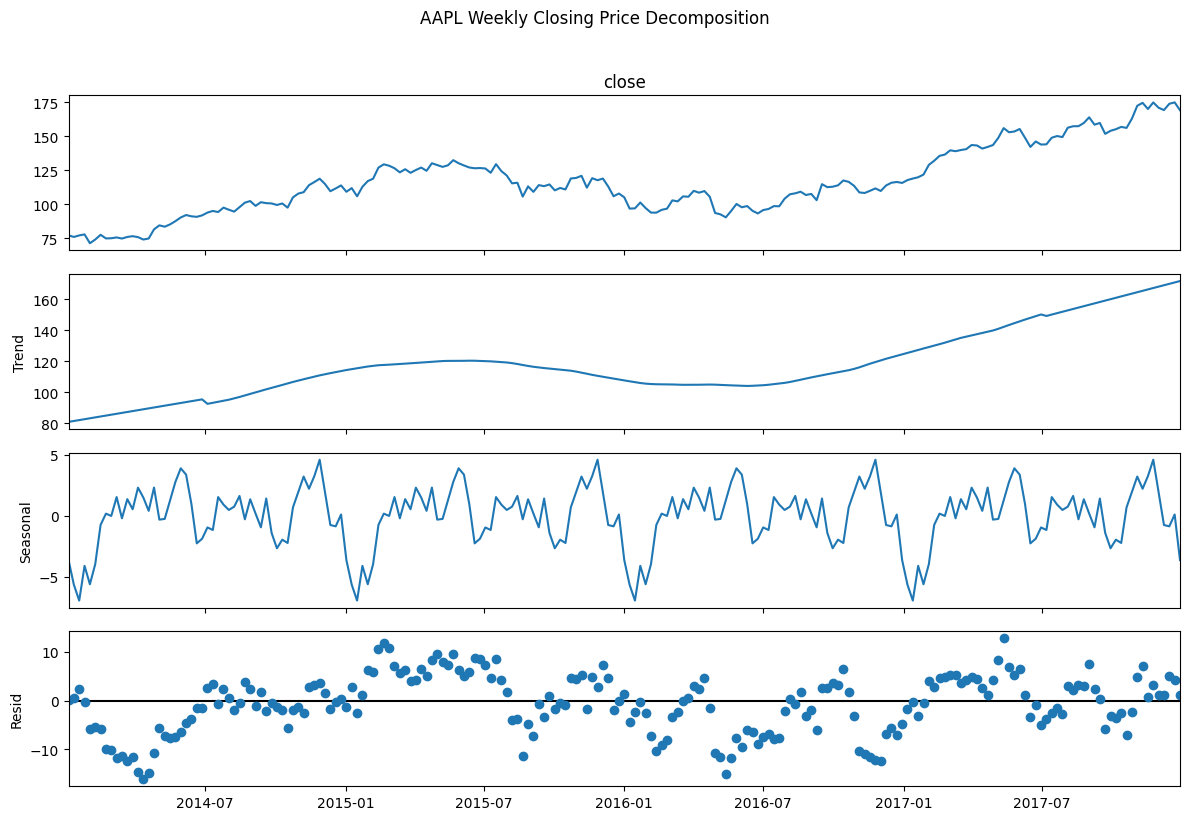

In [5]:
decomposition = seasonal_decompose(
    weekly_close,
    model="additive",
    period=52,
    extrapolate_trend="freq"
)

fig = decomposition.plot()
fig.set_size_inches(12, 8)
fig.suptitle("AAPL Weekly Closing Price Decomposition", y=1.02)
plt.tight_layout()
plt.show()

## 4. Apply and plot a moving average

A 4-week rolling mean smooths short-term variation while retaining the original weekly series for comparison.

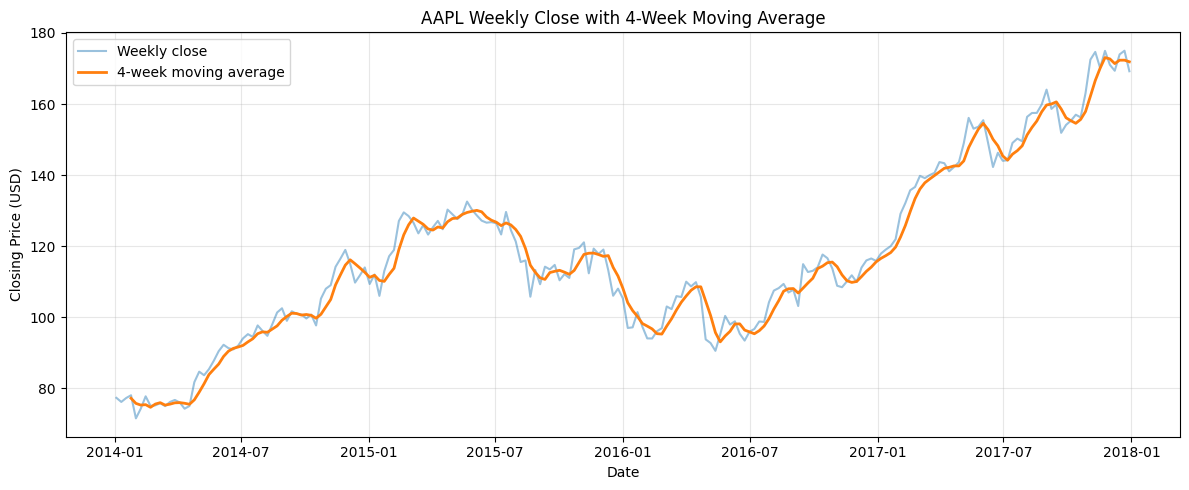

In [6]:
moving_average_4w = weekly_close.rolling(window=4).mean()

plt.figure(figsize=(12, 5))
plt.plot(weekly_close.index, weekly_close.values, alpha=0.45, label="Weekly close")
plt.plot(moving_average_4w.index, moving_average_4w.values, linewidth=2, label="4-week moving average")
plt.title("AAPL Weekly Close with 4-Week Moving Average")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Task 2 checklist

- [x] Plot time-series data and inspect its patterns.
- [x] Decompose into trend, seasonality, and residuals with statsmodels.
- [x] Perform moving-average smoothing and plot the result.